# AutoExperiment - Credit Risk Application

**Finding the best model for bank default rates (TAP) using macroeconomic drivers**

This notebook demonstrates a realistic credit risk modeling workflow:
1. Panel of banks over time with default rates and macro variables
2. Economic sign constraints from theory
3. AutoExperiment with transformations
4. Comparison with manual models (FE, RE)
5. Discussion: data mining vs. economic theory

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from panelbox import AutoExperiment
from panelbox.experiment import PanelExperiment

---
## 1. Load Credit Risk Data

We simulate a panel of 15 banks over 40 quarters with:

| Variable | Description | Expected Sign on TAP |
|----------|-------------|---------------------|
| `tap` | Default rate (Taxa de Aprovisionamento) | Dependent variable |
| `selic` | Base interest rate | (+) Higher rates -> more defaults |
| `ibc_br` | Economic activity index (IBC-Br) | (-) More activity -> fewer defaults |
| `spread` | Credit spread | (+) Higher spread -> more defaults |
| `tax_desemp` | Unemployment rate | (+) More unemployment -> more defaults |
| `ipca` | Inflation rate | (+/-) Ambiguous |
| `cambio` | Exchange rate (BRL/USD) | (+) Depreciation -> more defaults |

In [2]:
# Generate synthetic credit risk panel data
rng = np.random.default_rng(2026)

N_BANKS = 15
T_QUARTERS = 40
N = N_BANKS * T_QUARTERS

bank_ids = np.repeat(np.arange(1, N_BANKS + 1), T_QUARTERS)
quarters = np.tile(np.arange(1, T_QUARTERS + 1), N_BANKS)

# Bank-specific fixed effects (risk profile)
bank_fe = rng.normal(0, 1.5, N_BANKS)
bank_effects = np.repeat(bank_fe, T_QUARTERS)

# Macro variables (common across banks, with some noise per bank)
base_selic = 8.0 + 3.0 * np.sin(np.linspace(0, 4 * np.pi, T_QUARTERS)) + rng.normal(0, 0.5, T_QUARTERS)
base_ibc = 100 + 10 * np.cos(np.linspace(0, 3 * np.pi, T_QUARTERS)) + np.linspace(0, 15, T_QUARTERS)
base_spread = 15 + 5 * np.sin(np.linspace(0.5, 5 * np.pi, T_QUARTERS)) + rng.normal(0, 1, T_QUARTERS)
base_desemp = 10 + 3 * np.sin(np.linspace(1, 3.5 * np.pi, T_QUARTERS)) + rng.normal(0, 0.3, T_QUARTERS)
base_ipca = 4.0 + 2.0 * np.sin(np.linspace(0, 2 * np.pi, T_QUARTERS)) + rng.normal(0, 0.3, T_QUARTERS)
base_cambio = 4.5 + 1.0 * np.sin(np.linspace(0, 3 * np.pi, T_QUARTERS)) + np.linspace(0, 1, T_QUARTERS)

selic = np.tile(base_selic, N_BANKS) + rng.normal(0, 0.1, N)
ibc_br = np.tile(base_ibc, N_BANKS) + rng.normal(0, 2, N)
spread = np.tile(base_spread, N_BANKS) + rng.normal(0, 0.5, N)
tax_desemp = np.tile(base_desemp, N_BANKS) + rng.normal(0, 0.2, N)
ipca = np.tile(base_ipca, N_BANKS) + rng.normal(0, 0.2, N)
cambio = np.tile(base_cambio, N_BANKS) + rng.normal(0, 0.1, N)

# TAP (default rate) = f(macro) + bank FE + noise
# DGP: selic(+), ibc_br(-), spread(+), tax_desemp(+)
tap = (
    2.0
    + 0.25 * selic           # (+) higher rates -> more defaults
    - 0.08 * ibc_br          # (-) more activity -> fewer defaults
    + 0.15 * spread           # (+) higher spread -> more defaults
    + 0.30 * tax_desemp       # (+) more unemployment -> more defaults
    + 0.05 * ipca             # small positive effect
    + bank_effects
    + rng.normal(0, 0.8, N)
)
tap = np.clip(tap, 0.1, None)  # Default rate >= 0.1%

credit_data = pd.DataFrame({
    'bank': bank_ids,
    'quarter': quarters,
    'tap': np.round(tap, 4),
    'selic': np.round(selic, 2),
    'ibc_br': np.round(ibc_br, 2),
    'spread': np.round(spread, 2),
    'tax_desemp': np.round(tax_desemp, 2),
    'ipca': np.round(ipca, 2),
    'cambio': np.round(cambio, 2),
})

print(f"Panel: {N_BANKS} banks x {T_QUARTERS} quarters = {len(credit_data)} obs")
credit_data.head()

Panel: 15 banks x 40 quarters = 600 obs


,bank,quarter,tap,selic,ibc_br,spread,tax_desemp,ipca,cambio
0,1,1,0.6170,7.52,111.76,18.58,13.28,4.73,4.54
1,1,2,1.2956,8.89,107.38,18.11,12.97,4.62,4.72
2,1,3,2.7565,10.03,108.40,20.78,13.19,5.39,5.02
3,1,4,1.2575,10.41,108.74,21.41,12.76,4.91,5.15
4,1,5,0.7010,10.39,106.78,18.39,12.32,4.51,5.44


In [3]:
credit_data.describe().round(2)

,bank,quarter,tap,selic,ibc_br,spread,tax_desemp,ipca,cambio
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,8.00,20.50,1.32,8.17,107.37,15.36,10.15,4.06,5.21
std,4.32,11.55,1.27,1.99,8.06,3.67,2.26,1.40,0.74
min,1.00,1.00,0.10,4.33,89.73,8.64,6.14,1.26,3.74
25%,4.00,10.75,0.10,6.47,100.91,11.94,7.82,2.88,4.54
50%,8.00,20.50,1.03,8.16,107.17,15.80,10.12,4.01,5.32
75%,12.00,30.25,2.05,10.01,113.35,18.34,12.40,5.23,5.77
max,15.00,40.00,6.57,11.63,124.98,22.28,13.61,6.96,6.52


---
## 2. Motivation: Finding the Best Model for TAP

Credit risk modelers need to:
- Identify which macro variables drive default rates
- Choose the right panel estimator (FE vs RE)
- Validate the model econometrically
- Ensure coefficients match economic intuition

AutoExperiment automates all of this.

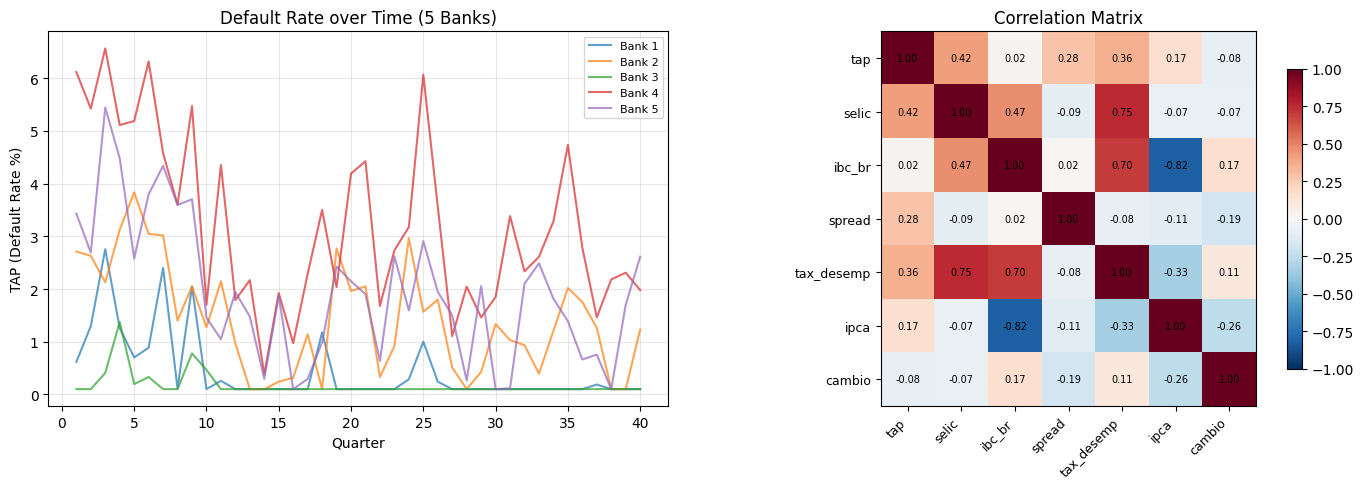

In [4]:
# Visualize TAP across banks
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for bank_id in credit_data['bank'].unique()[:5]:
    bank_df = credit_data[credit_data['bank'] == bank_id]
    axes[0].plot(bank_df['quarter'], bank_df['tap'], alpha=0.7, label=f'Bank {bank_id}')
axes[0].set_xlabel('Quarter')
axes[0].set_ylabel('TAP (Default Rate %)')
axes[0].set_title('Default Rate over Time (5 Banks)')
axes[0].legend(fontsize=8)
axes[0].grid(True, alpha=0.3)

# Correlation heatmap
macro_cols = ['tap', 'selic', 'ibc_br', 'spread', 'tax_desemp', 'ipca', 'cambio']
corr = credit_data[macro_cols].corr()
im = axes[1].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[1].set_xticks(range(len(macro_cols)))
axes[1].set_yticks(range(len(macro_cols)))
axes[1].set_xticklabels(macro_cols, rotation=45, ha='right', fontsize=9)
axes[1].set_yticklabels(macro_cols, fontsize=9)
axes[1].set_title('Correlation Matrix')
for i in range(len(macro_cols)):
    for j in range(len(macro_cols)):
        axes[1].text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=axes[1], shrink=0.8)

plt.tight_layout()
plt.show()

---
## 3. Define Candidates and Sign Constraints

From credit risk theory:
- **Selic (+)**: Higher interest rates increase debt servicing costs
- **IBC-Br (-)**: Economic activity reduces defaults
- **Spread (+)**: Higher credit spreads reflect risk and cause more defaults
- **Unemployment (+)**: More unemployment -> more defaults

In [5]:
CANDIDATES = ['selic', 'ibc_br', 'spread', 'tax_desemp', 'ipca', 'cambio']

SIGN_CONSTRAINTS = {
    'selic': '+',
    'ibc_br': '-',
    'spread': '+',
    'tax_desemp': '+',
}

print("Candidate variables:", CANDIDATES)
print("Sign constraints:", SIGN_CONSTRAINTS)

Candidate variables: ['selic', 'ibc_br', 'spread', 'tax_desemp', 'ipca', 'cambio']
Sign constraints: {'selic': '+', 'ibc_br': '-', 'spread': '+', 'tax_desemp': '+'}


---
## 4. Run AutoExperiment with Transformations

In [6]:
auto = AutoExperiment(
    data=credit_data,
    depvar='tap',
    entity_col='bank',
    time_col='quarter',
    candidates=CANDIDATES,
    transformations={
        'lag': [1, 2],
        'diff': True,
        'growth': True,
    },
    sign_constraints=SIGN_CONSTRAINTS,
    models=['pooled_ols', 'fe', 're', 'fd'],
    criterion='bic',
    max_vars=6,
    max_combinations=300,
    verbose=1,
)

results = auto.run()

Phase 1: Variable transformations
  6 original + 18 transformed = 24 candidates
Phase 2: Forward stepwise selection
  Selecting for pooled_ols...
  [------------------------------] 0/4 Selection

  Selecting for fe...
  [#######-----------------------] 1/4 Selection

  Selecting for re...
  [###############---------------] 2/4 Selection

  Selecting for fd...
  [######################--------] 3/4 Selection

  [##############################] 4/4 Selection


...

    -> WARNING (BIC=10.34, cov=robust)
  [#######-----------------------] 1/4 Estimation

    -> INVALID (BIC=-381.32, cov=driscoll_kraay)
  [###############---------------] 2/4 Estimation

    -> INVALID (BIC=37.34, cov=driscoll_kraay)
  [######################--------] 3/4 Estimation

    -> VALID (BIC=nan, cov=nonrobust)
  [##############################] 4/4 Estimation


Phase 4: Hausman test (FE vs RE)
  Hausman: prefer RE (marked fe_selic_spread_ipca_tax_desemp_cambio as WARNING)
Phase 5: Ranking
Done.


---
## 5. Interpret Results

In [7]:
print(results.summary())

══════════════════════════════════════════════════
AutoExperiment Results
══════════════════════════════════════════════════
Best model: First Difference
Formula:    tap ~ selic + spread + ipca + tax_desemp + cambio
BIC:        10.3
R-squared:  0.386
Cov type:   nonrobust
Status:     VALID (all tests passed)
──────────────────────────────────────────────────
Models tested:     4
Combinations:      84
Variables tested:  20
Transformations:   3 types


In [8]:
# Top 5 models
results.compare_top(n=5)

,model_type,formula,bic,aic,rsq,rsq_adj,classification,n_vars,cov_type,score
0,fe,tap ~ selic + spread + ipca + tax_desemp + cambio,-381.324321,-403.308969,0.547074,0.532236,INVALID,5,driscoll_kraay,-183.324321
1,pooled_ols,tap ~ selic + spread + L2_ipca + L2_tax_desemp...,10.335860,-15.737958,0.386132,0.380690,WARNING,5,robust,58.335860
2,re,tap ~ selic + spread + ipca + tax_desemp,37.338516,15.353868,0.372030,0.367809,INVALID,4,driscoll_kraay,233.338516
3,fd,tap ~ selic + spread + ipca + tax_desemp + cambio,NaN,NaN,0.104141,0.097963,VALID,5,nonrobust,NaN


In [9]:
# Best model details
print(f"Best estimator: {results.best_estimator}")
print(f"Best formula:   {results.best_formula}")
print(f"Cov type:       {results.best_cov_type}")
print()
if results.best_model is not None:
    print(results.best_model.summary())

Best estimator: fd
Best formula:   tap ~ selic + spread + ipca + tax_desemp + cambio
Cov type:       nonrobust

                     First Difference Estimation Results                      
Formula: tap ~ selic + spread + ipca + tax_desemp + cambio
Model:   First Difference
------------------------------------------------------------------------------
No. Observations:                 585
No. Entities:                      15
No. Time Periods:                  40
Degrees of Freedom:               580
R-squared:                     0.1041
Adj. R-squared:                0.0980
R-squared (within):            0.1041
Standard Errors:            nonrobust
Variable        Coef.        Std.Err.     t        P>|t|    [0.025     0.975]    
------------------------------------------------------------------------------
selic                0.2327      0.0416   5.599  0.0000    0.1511    0.3144 ***
spread               0.0948      0.0193   4.901  0.0000    0.0568    0.1328 ***
ipca                

In [10]:
# Variable selection details
for model_type, sel in results.variable_selection.items():
    selected = sel.get('selected_vars', [])
    print(f"{model_type}: {selected}")

pooled_ols: ['selic', 'spread', 'L2_ipca', 'L2_tax_desemp', 'L1_ipca']
fe: ['selic', 'spread', 'ipca', 'tax_desemp', 'cambio']
re: ['selic', 'spread', 'ipca', 'tax_desemp']
fd: ['selic', 'spread', 'ipca', 'tax_desemp', 'cambio']


In [11]:
# Diagnostic tests
for name, tests in results.test_results.items():
    status = tests['classification']
    failed = tests['failed']
    print(f"{name}: {status}" + (f" (failed: {failed})" if failed else ""))

pooled_ols_selic_spread_L2_ipca_L2_tax_desemp_L1_ipca: WARNING (failed: ['Breusch-Pagan'])
fe_selic_spread_ipca_tax_desemp_cambio: INVALID (failed: ['Pesaran CD', 'Modified Wald', 'RESET'])
re_selic_spread_ipca_tax_desemp: INVALID (failed: ['Breusch-Pagan', 'RESET'])
fd_selic_spread_ipca_tax_desemp_cambio: VALID


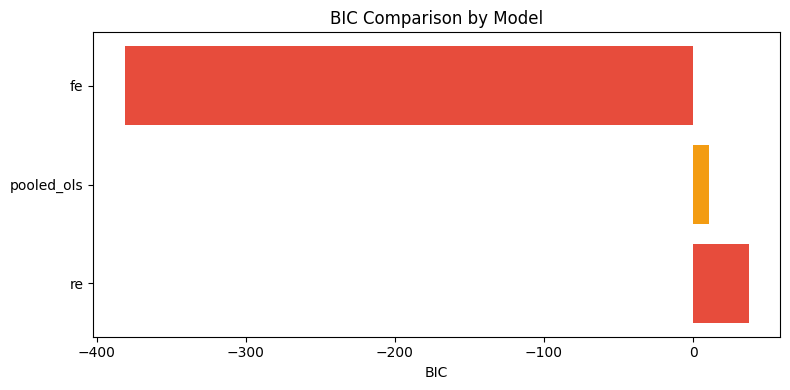

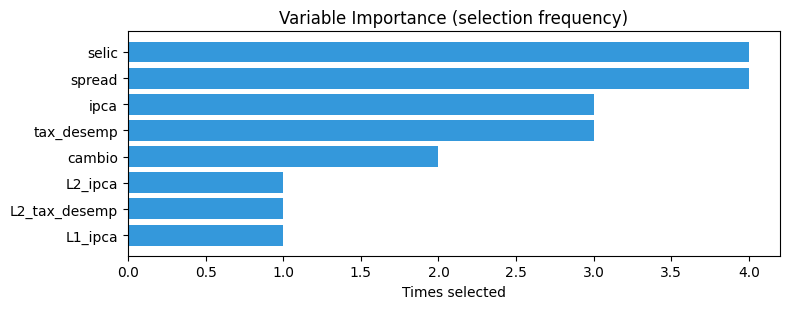

In [12]:
# Plots
fig = results.plot_bic_comparison()
if fig:
    plt.show()

fig = results.plot_variable_importance()
if fig:
    plt.show()

---
## 6. Compare with Manual Models (FE, RE)

Let's fit FE and RE manually with all candidate variables and compare.

In [13]:
# Manual models using PanelExperiment
formula_all = "tap ~ selic + ibc_br + spread + tax_desemp + ipca + cambio"

experiment = PanelExperiment(
    data=credit_data,
    formula=formula_all,
    entity_col='bank',
    time_col='quarter',
)

experiment.fit_model('fixed_effects', name='manual_fe')
experiment.fit_model('random_effects', name='manual_re')

comparison = experiment.compare_models()
print(comparison)

ComparisonResult(
  n_models=2,
  models=['manual_fe', 'manual_re'],
  timestamp=2026-03-28T22:35:35.611814
)

In [14]:
# Compare: manual FE vs AutoExperiment best
manual_fe = experiment.get_model('manual_fe')

print("=" * 60)
print("MANUAL FE (all variables)")
print("=" * 60)
print(f"Formula: {formula_all}")
print(manual_fe.summary())

print("\n" + "=" * 60)
print("AUTOEXPERIMENT BEST")
print("=" * 60)
print(f"Model:   {results.best_estimator}")
print(f"Formula: {results.best_formula}")
print(f"Cov:     {results.best_cov_type}")
if results.best_model is not None:
    print(results.best_model.summary())

MANUAL FE (all variables)
Formula: tap ~ selic + ibc_br + spread + tax_desemp + ipca + cambio
                       Fixed Effects Estimation Results                       
Formula: tap ~ selic + ibc_br + spread + tax_desemp + ipca + cambio
Model:   Fixed Effects
------------------------------------------------------------------------------
No. Observations:                 600
No. Entities:                      15
No. Time Periods:                  40
Degrees of Freedom:               579
R-squared:                     0.5691
Adj. R-squared:                0.5542
R-squared (within):            0.5691
R-squared (between):           1.0000
R-squared (overall):           0.7027
Standard Errors:            nonrobust
F-statistic (FE vs OLS):      43.1095
F-test p-value:                0.0000
Variable        Coef.        Std.Err.     t        P>|t|    [0.025     0.975]    
------------------------------------------------------------------------------
selic                0.1964      0.0238 

---
## 7. Generate Final Report

In [15]:
html = results.report(filepath='autoexperiment_credit_risk_report.html')
print(f"Report saved: autoexperiment_credit_risk_report.html ({len(html):,} chars)")

Report saved: autoexperiment_credit_risk_report.html (3,366 chars)


---
## 8. Discussion: Data Mining vs. Economic Theory

### The Data Mining Risk

AutoExperiment tests many variable combinations. This creates a risk of **data mining** — finding spurious relationships that don't generalize.

### How AutoExperiment Mitigates This

1. **Sign constraints**: Models with economically implausible signs are penalized
2. **Econometric validation**: RESET, Hausman, heteroskedasticity tests filter bad specs
3. **Data mining warning**: Alerts when > 100 combinations are tested
4. **BIC penalty**: BIC naturally penalizes overfitting (stronger than AIC)
5. **Transparency**: Full audit trail of tested combinations and rejected variables

### Best Practices

- Always start with **economic theory** to define candidates and sign constraints
- Use **out-of-sample validation** to confirm results
- Prefer **parsimonious models** (fewer variables = more robust)
- Treat AutoExperiment as a **screening tool**, not the final word

In [16]:
print(f"Data mining warning: {results.datamining_warning}")
print(f"Combinations tested: {results.n_combinations_tested}")
print(f"Models in ranking:   {len(results.ranking)}")
print()
print("Transformations used:")
for var, (source, ttype) in results.transformations_used.items():
    print(f"  {var} <- {source} ({ttype})")

Data mining warning: False
Combinations tested: 84
Models in ranking:   4

Transformations used:
  L1_selic <- selic (lag1)
  L2_selic <- selic (lag2)
  D_selic <- selic (diff)
  L1_ibc_br <- ibc_br (lag1)
  L2_ibc_br <- ibc_br (lag2)
  D_ibc_br <- ibc_br (diff)
  L1_spread <- spread (lag1)
  L2_spread <- spread (lag2)
  D_spread <- spread (diff)
  L1_tax_desemp <- tax_desemp (lag1)
  L2_tax_desemp <- tax_desemp (lag2)
  D_tax_desemp <- tax_desemp (diff)
  L1_ipca <- ipca (lag1)
  L2_ipca <- ipca (lag2)
  D_ipca <- ipca (diff)
  growth_ipca <- ipca (growth)
  L1_cambio <- cambio (lag1)
  D_cambio <- cambio (diff)


## Summary

This notebook demonstrated a credit risk modeling workflow with AutoExperiment:

- **Economic theory** guided the candidate selection and sign constraints
- **AutoExperiment** automated variable selection, estimation, and validation
- **Manual comparison** showed that AutoExperiment can find more parsimonious models
- **Transparency** features help guard against data mining

AutoExperiment is a powerful tool for systematic model selection, but it should always be combined with domain knowledge and out-of-sample validation.